In [1]:
import csv
from collections import Counter
from pathlib import Path

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

counts = Counter()

with open(CSV_FILE, "r", newline="", encoding="utf-8") as file:
    reader = csv.reader(file)

    # Skip header
    next(reader)

    # Read only the first column
    for row in reader:
        if row:
            label = row[0].strip()
            counts[label] += 1


print("PQD-16C DATASET CLASS DISTRIBUTION")
print("=" * 45)
print()

for label, count in sorted(counts.items()):
    print(f"{label}: {count}")

print()
print("=" * 45)
print(f"Total samples: {sum(counts.values())}")
print(f"Total classes: {len(counts)}")

PQD-16C DATASET CLASS DISTRIBUTION

Flicker: 100
Flicker+Harmonics: 100
Flicker+Sag: 100
Flicker+Swell: 100
Harmonics: 100
Impulsive Transient: 100
Interruption: 100
Interruption+Harmonics: 100
Normal: 100
Notch: 100
Oscillatory transient: 100
Sag: 100
Sag+Harmonics: 100
Spike: 100
Swell: 100
Swell+Harmonics: 100

Total samples: 1600
Total classes: 16


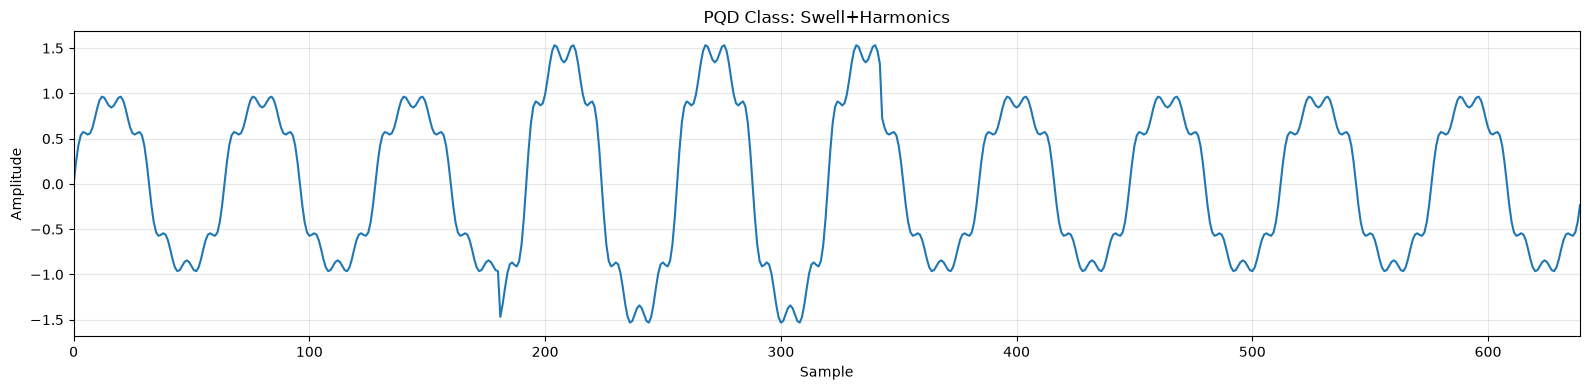

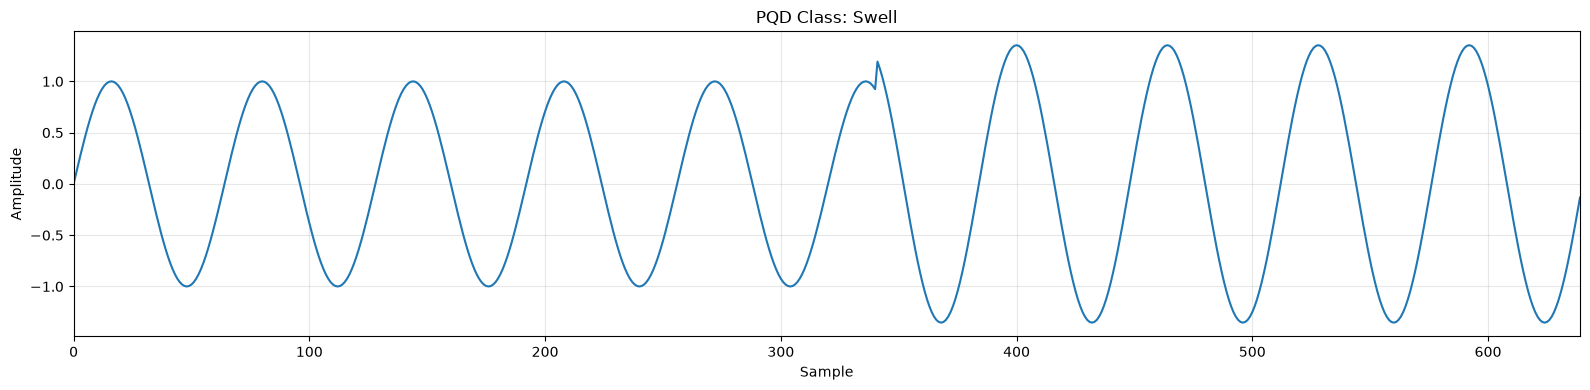

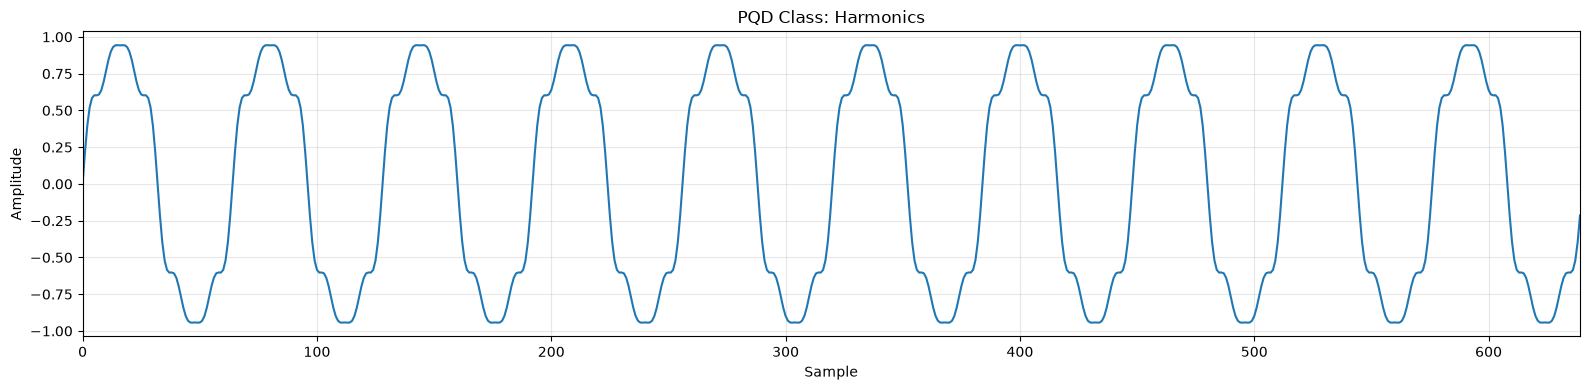

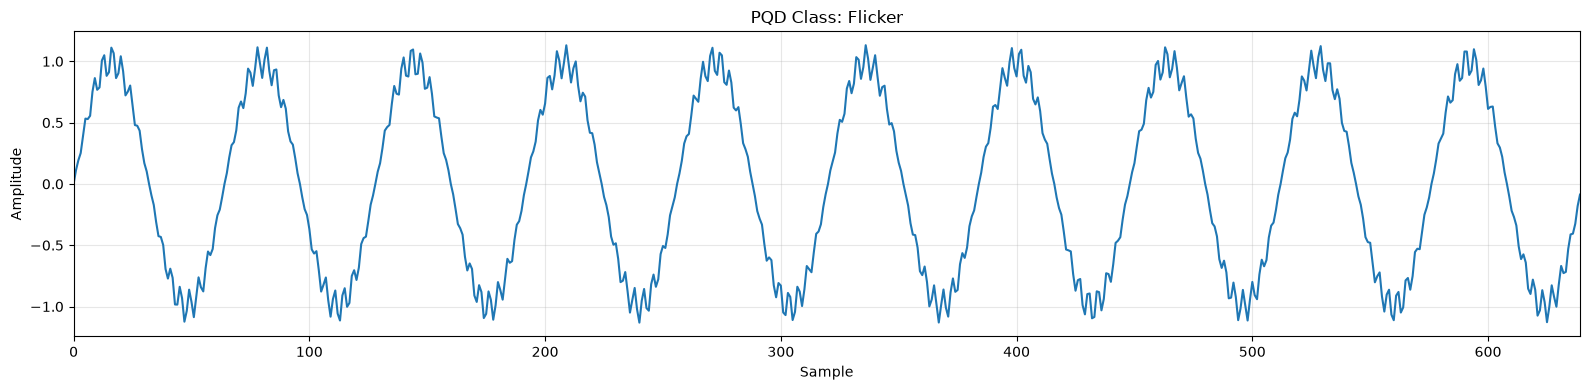

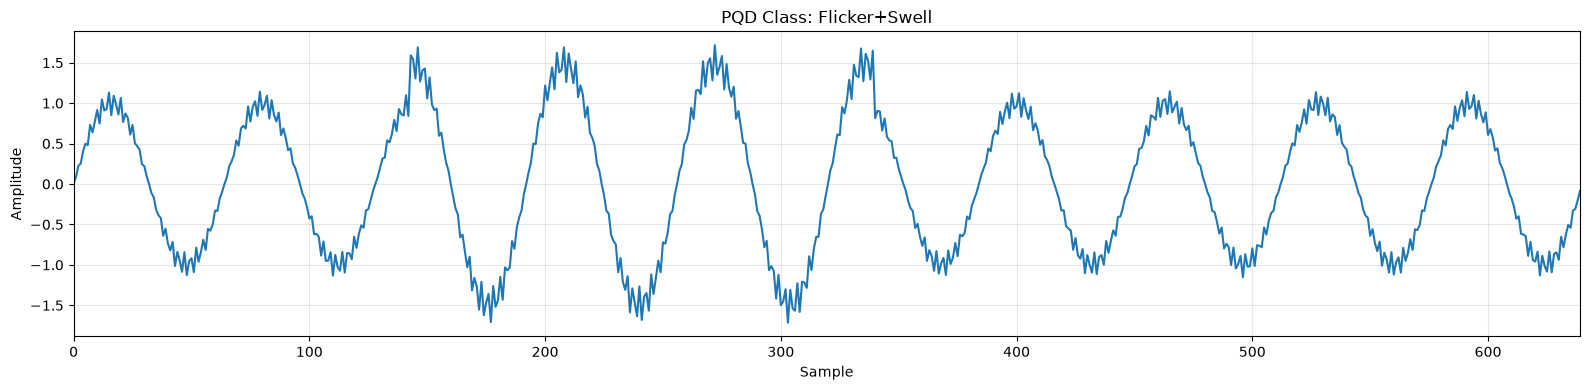

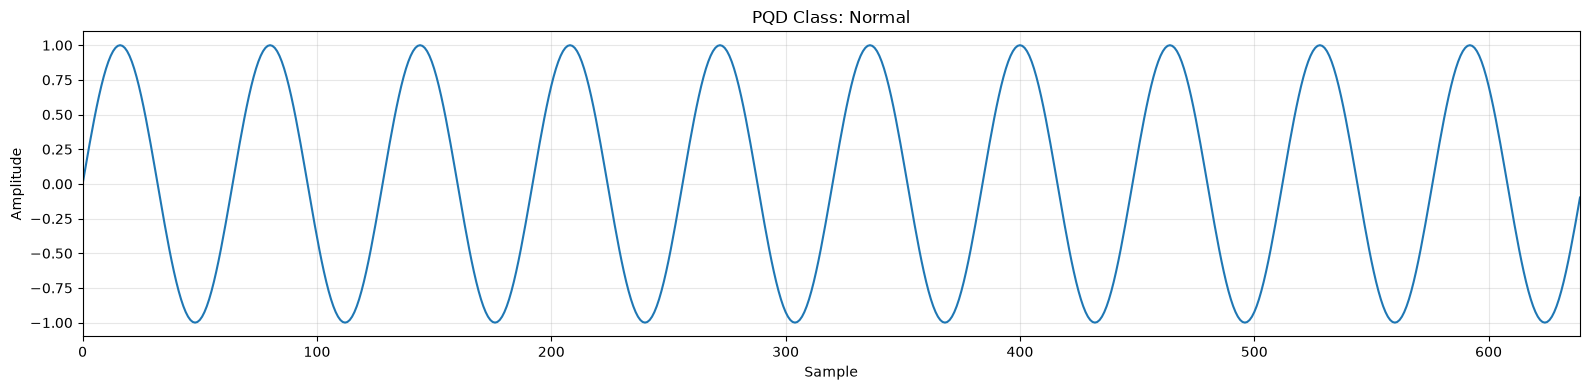

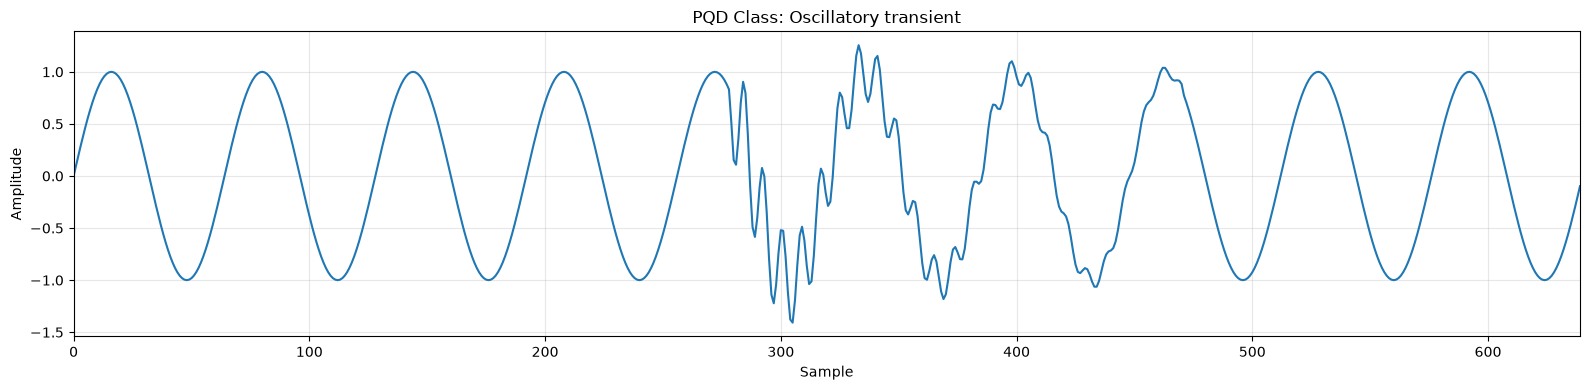

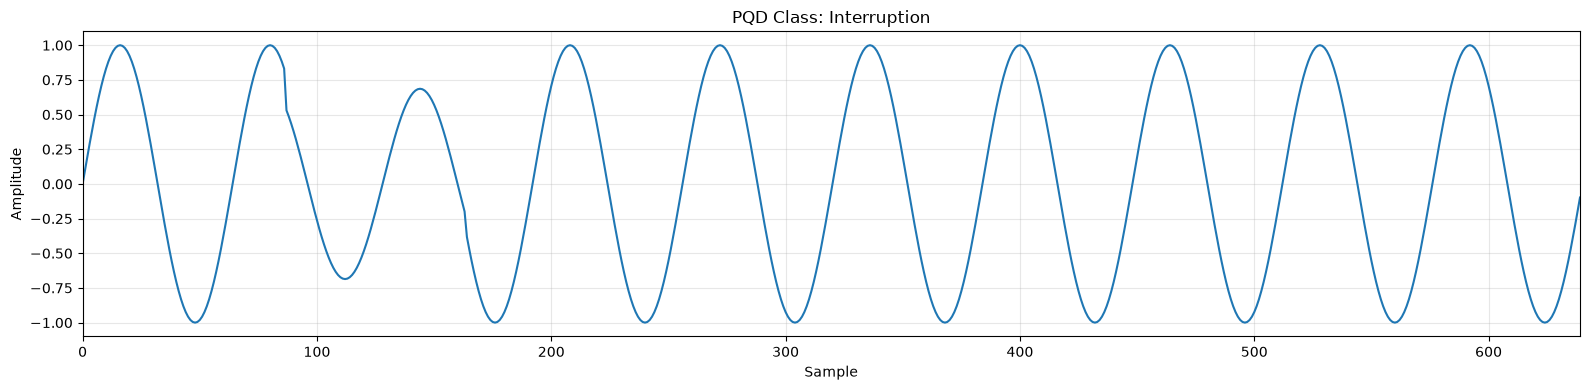

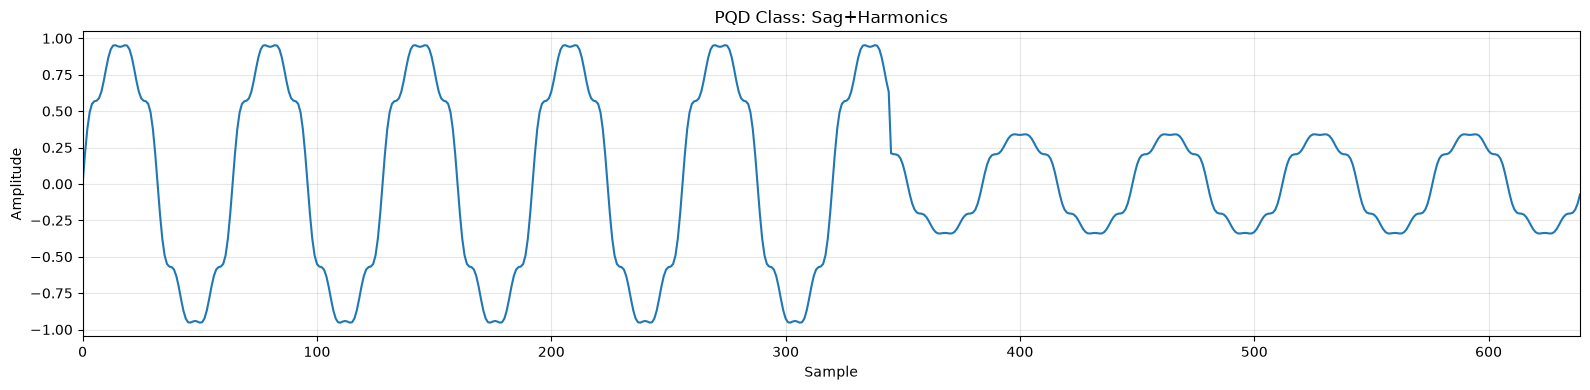

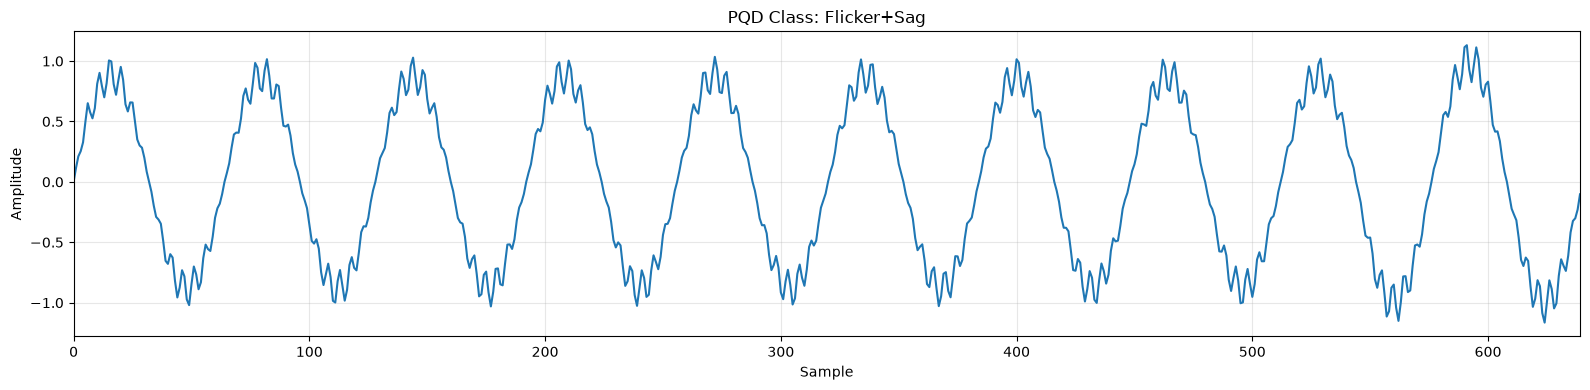

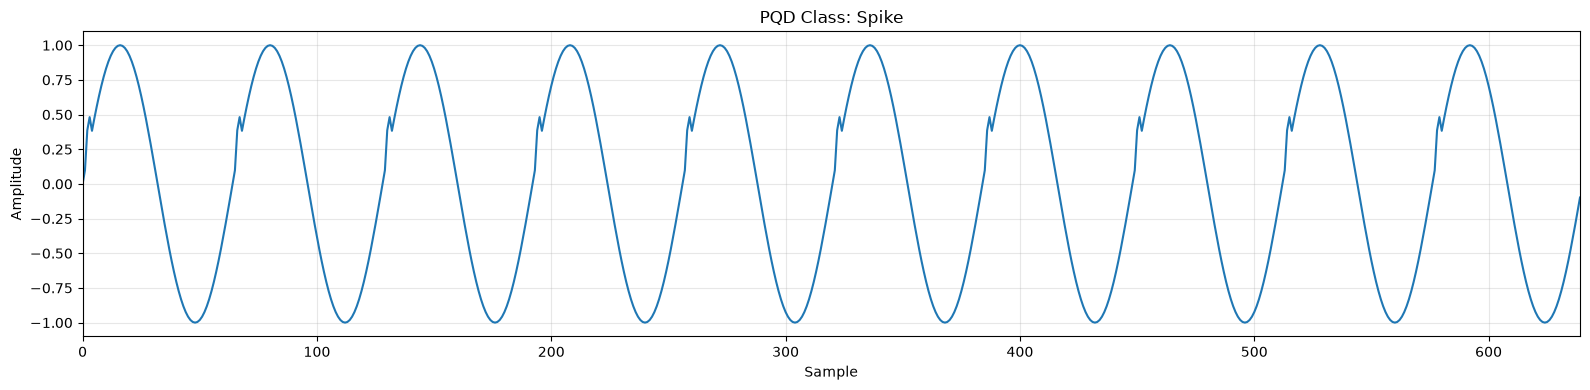

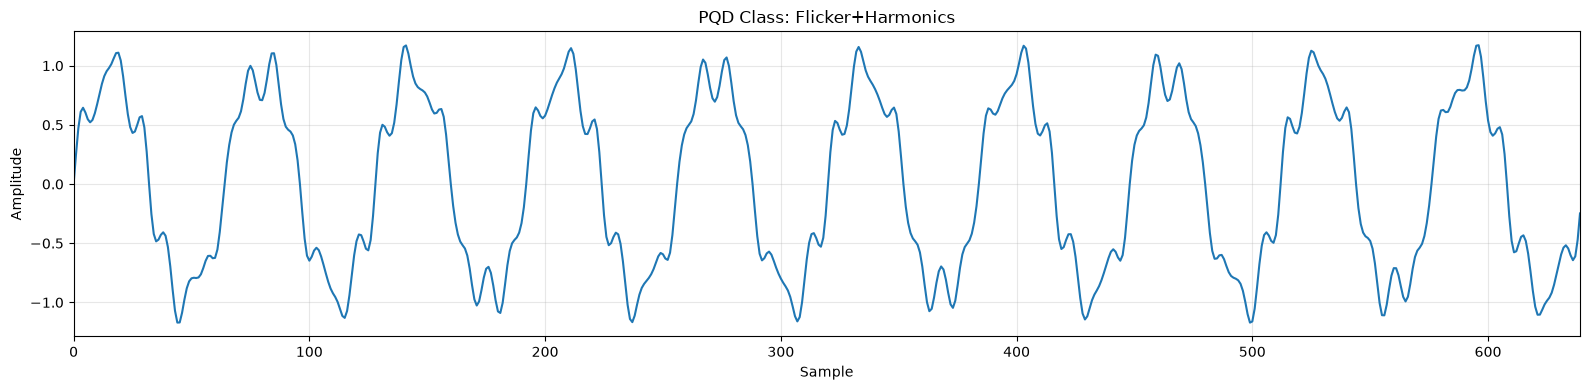

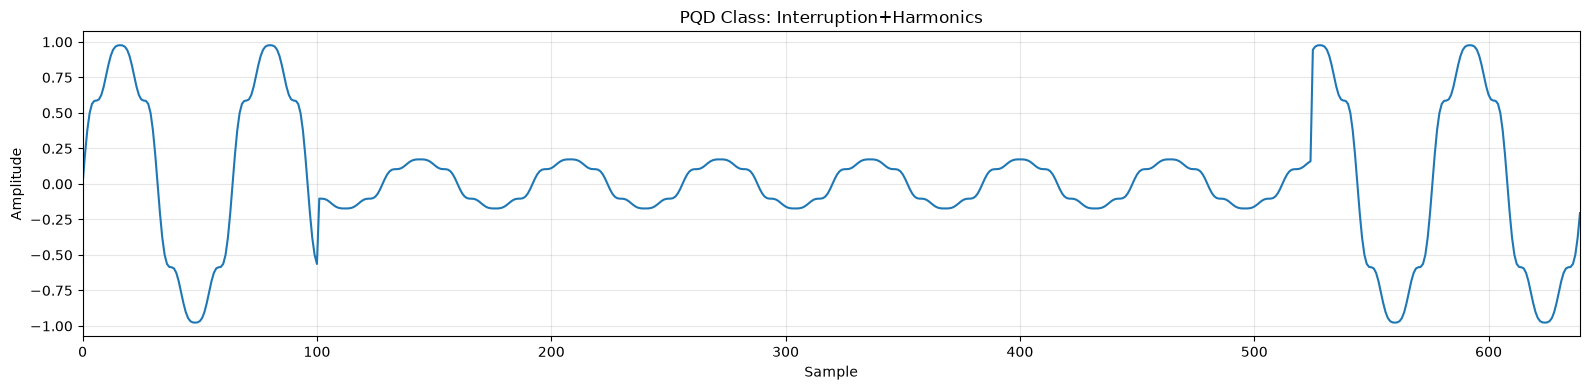

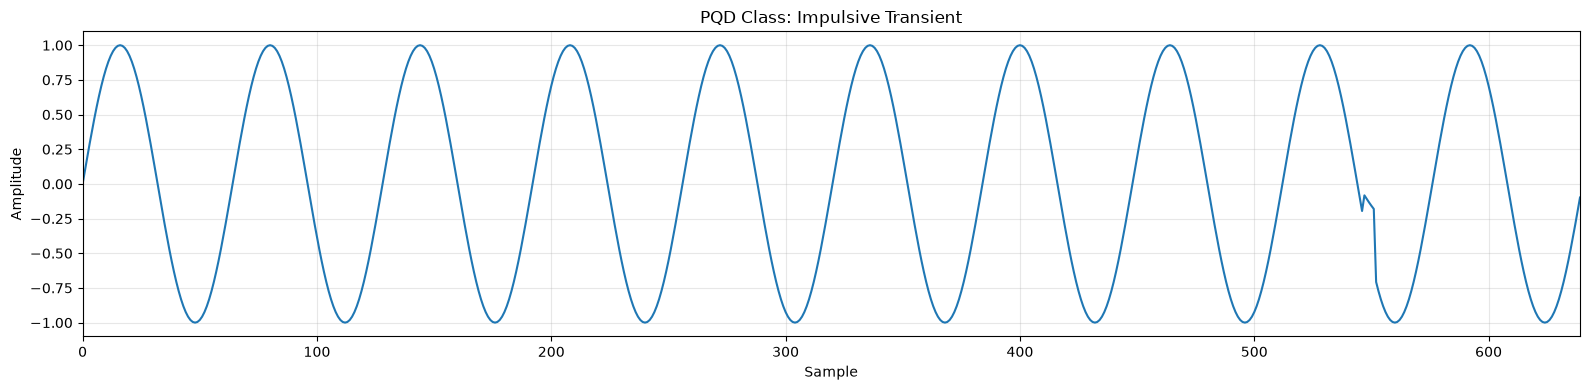

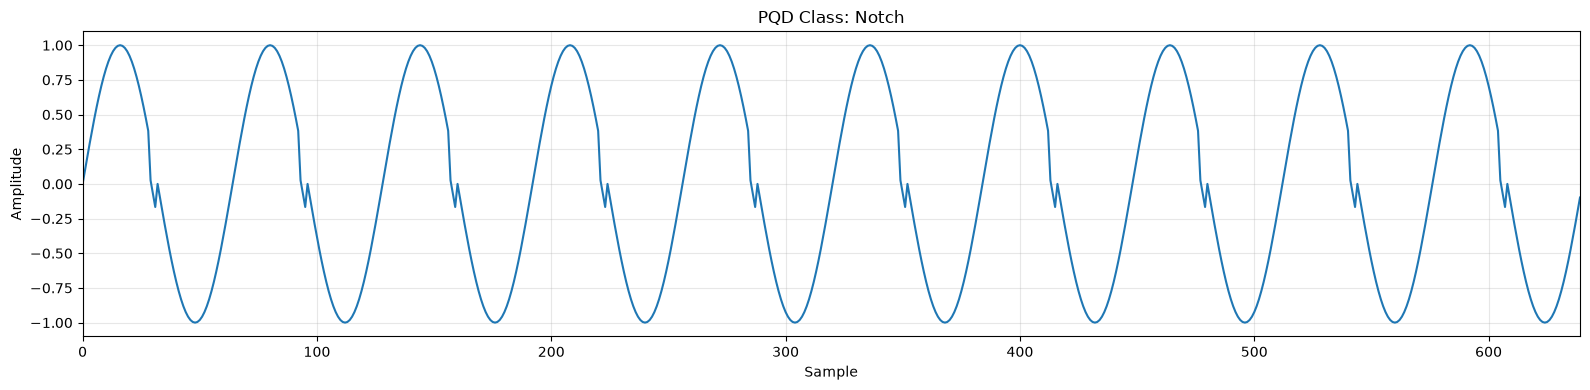

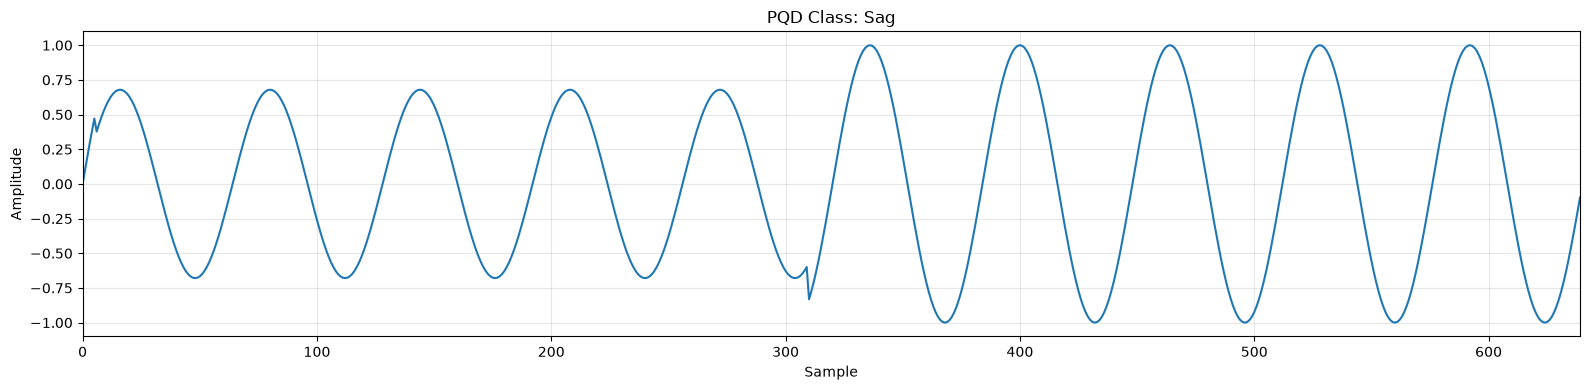

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# Configuration
# --------------------------------------------------

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

# --------------------------------------------------
# Load dataset
# --------------------------------------------------

df = pd.read_csv(CSV_FILE)

label_column = df.columns[0]
signal_columns = df.columns[1:]

# --------------------------------------------------
# Plot one random waveform from each class
# --------------------------------------------------

for label in df[label_column].unique():

    # Get all samples belonging to this class
    class_samples = df[df[label_column] == label]

    # Select one random waveform
    row = class_samples.sample(n=1).iloc[0]

    # Extract the 640 signal samples
    signal = row[signal_columns].astype(float).values

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    plt.figure(figsize=(16, 4))

    plt.plot(signal)

    plt.title(f"PQD Class: {label}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.xlim(0, 639)

    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.show()